<img src = "https://drive.google.com/uc?export=view&id=10DJdk95gzrY6H-dKEFKshN814gdMc9FV" alt = "Encabezado MLDS" width = "100%">  </img>

# **Entendimiento y Preparación de los Datos**
---

Este notebook es una plantilla que le puede servir como guía para el segundo entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. MARINA ANTOLÍNEZ CABRERO
2. JORGE ESAU TIERRADENTRO CRUZ

## **1. Análisis Exploratorio de los Datos**
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

### **1.1. Resumen General**
---

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

Contamos con 72 archivos de registro. 2 por cada uno de los 36 sujetos.
Aunque cabe destacar que en el código aparecen 73, esto se debe al README.

\
El volumen de datos es de 4.237.908 filas x 12 columnas, y estos se almacenan en archivos de texto plano **`.txt`** con columnas separadas por espacios en blanco. Cada columna contiene 10 columnas: tiempo_ms, canal_1 ... canal_8, clase.

\
Tamaño en disco: 250.82 MB

Tamaño en memoria: 642.61 MB

### **1.2. Resumen de la Calidad de los datos**
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

Se detectan datos faltantes, pero solo uno.
La verificación imprime que hay un valor nulo. Esto se debe a que la columna clase cuenta con un dato menos frente a los demás.
Pero no se detecta ningún documento vacío.
Respecto a la calidad, hay un dato problemático en nuestro dataset, y es que el 64% de las muestras están sin marcar (clase 0), y la clase 7 (palma extendida) solo aparece en 2 de los 36 sujetos.

LA idea era tratar este probelma en el alcance, excluyendo ambos casos.

\
No contamos con documentos ilegibles. Al ser ficheros numéricos la codificación y decodificación no es un riesgo real.

\
No contamos con diversos formatos, todos los archivos con **`.txt`**.
Igualmente, a modo de control, nuestro código descarta cualquier archivo cuyo número de columnas no coincida, y aún así no se descartó ninguno.
Nuetsros datos también tienen formatos coherentes:
- tiempo_ms int
- los 8 canales float64
- clase float64

\
Nuestro problema en el planteamiento inicial es que se detectan los datos faltantes, atípicos o cuplicados pero no se trataron.
Ejemplo:
- Faltantes: se detecta un único valor nulo, pero no se resuelve
- Atípicos: todos los canales tienen un valor mínimo y máximo. Asumimos que se debe a un límite de saturación de los propios sensores, pero nos conviene comprobarlo.
- Duplicados: no se comprueban. En el head hay valores idénticos en los 8 canales.

Para poder resolverlo incluimos el siguiente código en nuestro programa anterior:

In [ ]:
import glob
import io
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 20)

URL_DATASET = "https://archive.ics.uci.edu/static/public/481/emg+data+for+gestures.zip"
CARPETA_DATOS = "emg_gestures"


def buscar_archivos(raiz, extension):
    """Devuelve todos los archivos con la extensión dada dentro de la carpeta
    (recursivo)."""

    return sorted(glob.glob(os.path.join(raiz, "**", f"*.{extension}"),
                            recursive=True))


def descargar_dataset(url=URL_DATASET, destino=CARPETA_DATOS):
    """Descarga y descomprime el dataset. No repite la descarga si ya existe."""

    if buscar_archivos(destino, "txt"):
        print(f"El dataset ya está en '{destino}'.")
        return

    os.makedirs(destino, exist_ok=True)
    peticion = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(peticion) as respuesta:
        contenido = respuesta.read()

    with zipfile.ZipFile(io.BytesIO(contenido)) as zip_externo:
        zip_externo.extractall(destino)

    # Por si el repositorio incluye un zip dentro del zip
    for zip_interno in buscar_archivos(destino, "zip"):
        with zipfile.ZipFile(zip_interno) as z:
            z.extractall(os.path.dirname(zip_interno))

    n_archivos = len([a for a in buscar_archivos(destino, "txt") if "readme" not in a.lower()])
    print(f"Descarga completada: {n_archivos} archivos de registros (sin contar el README).")

descargar_dataset()
COLUMNAS = ["tiempo_ms"] + [f"canal_{i}" for i in range(1, 9)] + ["clase"]

NOMBRES_GESTOS = {
    0: "sin marcar",
    1: "reposo",
    2: "puño cerrado",
    3: "flexión de muñeca",
    4: "extensión de muñeca",
    5: "desviación radial",
    6: "desviación cubital",
    7: "palma extendida",
}


def cargar_dataset(raiz=CARPETA_DATOS):
    """Lee todos los registros y devuelve un único DataFrame con el sujeto
    y el archivo de origen."""

    archivos = [a for a in buscar_archivos(raiz, "txt") if "readme" not in a.lower()]
    if not archivos:
        raise FileNotFoundError(f"No se encontraron archivos .txt en '{raiz}'.")

    tablas = []
    for ruta in archivos:
        tabla = pd.read_csv(ruta, sep=r"\s+")
        if tabla.shape[1] != len(COLUMNAS):
            print(f"Aviso: se omite {ruta} (tiene {tabla.shape[1]} columnas en lugar de {len(COLUMNAS)}).")
            continue
        tabla.columns = COLUMNAS
        tabla["sujeto"] = os.path.basename(os.path.dirname(ruta))
        tabla["archivo"] = os.path.basename(ruta)
        tablas.append(tabla)

    datos = pd.concat(tablas, ignore_index=True)
    datos["sujeto"] = datos["sujeto"].astype("category")
    return datos


datos = cargar_dataset()
datos.head()

Descarga completada: 72 archivos de registros (sin contar el README).


,tiempo_ms,canal_1,canal_2,canal_3,canal_4,canal_5,canal_6,canal_7,canal_8,clase,sujeto,archivo
0,1,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
1,5,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
2,6,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
3,7,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt
4,8,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0.0,01,1_raw_data_13-12_22.03.16.txt


In [ ]:
canales = [f"canal_{i}" for i in range(1, 9)]

# Faltantes
print(datos.isna().sum()[lambda s: s > 0])
print(datos[datos.isna().any(axis=1)][["archivo", "tiempo_ms", "clase"]])

# Archivos vacíos / tamaño de cada registro
filas_por_archivo = datos.groupby("archivo", observed=True).size()
print("Filas por archivo (mín / máx):", filas_por_archivo.min(), "/", filas_por_archivo.max())

# Duplicados
print("Filas duplicadas (todas las columnas):", datos.duplicated().sum())
print("Duplicadas ignorando el tiempo:", datos.duplicated(subset=canales + ["clase", "archivo"]).sum())

# Valores en el límite del sensor
saturadas = (datos[canales].abs() >= 0.00127).sum()
print((100 * saturadas / len(datos)).round(3))

clase    1
dtype: int64
                               archivo  tiempo_ms  clase
3985214  1_raw_data_10-51_07.04.16.txt      97144    NaN
Filas por archivo (mín / máx): 44927 / 79765
Filas duplicadas (todas las columnas): 0
Duplicadas ignorando el tiempo: 3776730
canal_1    0.072
canal_2    0.037
canal_3    0.022
canal_4    0.164
canal_5    0.271
canal_6    0.084
canal_7    0.056
canal_8    0.082
dtype: float64


Salida:


*clase    1*

*dtype: int64*

*archivo  tiempo_ms  clase*

*3985214  1_raw_data_10-51_07.04.16.*

*txt      97144    NaN*

*Filas por archivo (mín / máx): 44927 / 79765*

*Filas duplicadas (todas las columnas): 0*

*Duplicadas ignorando el tiempo: 3776730*

*canal_1    0.072*

*canal_2    0.037*

*canal_3    0.022*

*canal_4    0.164*

*canal_5    0.271*

*canal_6    0.084*

*canal_7    0.056*

*canal_8    0.082*

*dtype: float64*

\
Habiendo incluido este nuevo campo vemos lo siguiente:

- Faltantes: el único valor nulo tiene  un impacto despreciable, y al eliminar dicha fila, clase puede pasar directamente a entero.

- Atípicos: es posible que se deba a la saturación del sensor, pero también pueden ser picos reales de activación muscular.
Por ello decidimos conservar y documentar acerca de esto.

- Duplicados: ninguna fila se repite completa, dado que el campo del tiempo siempre es distinto.
Además casi todas las filas cuentan con valores muy similares. Esto nos permite descartar la idea de que sea un error, sino una tendencia.

### **1.3. Tipos de variables**

#### **1. Variable objetivo y su naturaleza**
* **Variable objetivo:** Sí, el conjunto de datos cuenta con una variable objetivo denominada `clase`.
* **Naturaleza:** Es una variable **categórica (multiclase)**, ya que representa gestos musculares o estados discreto codificados numéricamente del 0 al 7 (originalmente cargada como flotante debido a la presencia de un único registro nulo en el dataset, pero convertible a entero tras limpiar ese valor).

---

#### **2. Distribución de etiquetas y análisis de desbalanceo**
* **Distribución de las clases:**
  * **Clase 0 (Sin marcar / Reposo sin etiqueta):** Corresponde a aproximadamente el **64% del total de las muestras**, siendo la clase predominantemente mayoritaria.
  * **Clase 7 (Palma extendida):** Presenta un comportamiento atípico y sumamente reducido, estando registrada en únicamente **2 de los 36 sujetos** analizados.
  * **Clases activas (1 a 6):** Representan en conjunto el ~36% restante de las observaciones registradas.
* **Diagnóstico de desbalanceo:** Existe un **desbalanceo severo de datos**:
  * La **clase 0** domina la mayor parte del volumen de datos frente a cualquier gesto activo.
  * La **clase 7** carece de representatividad poblacional al manifestarse de manera aislada en solo dos sujetos, por lo que se eliminará del alcance para evitar sesgar el modelo.

---

#### **3. Variables adicionales y análisis descriptivo**

* **`tiempo_ms` (Secuencia temporal):**
  * **Tipo:** Continuo / Entero (`int64`).
  * **Descripción:** Indica la marca de tiempo en milisegundos en la que se tomó la muestra.
  * **Incorporación:** **No se incorporará directamente como variable de entrada (feature)** para el modelo de clasificación, pero es fundamental para conservar la secuencia cronológica al reconstruir ventanas temporales o segmentar episodios de movimiento.

* **`canal_1` a `canal_8` (Señales electromiográficas - EMG):**
  * **Tipo:** Continuas (`float64`).
  * **Descripción:** Corresponden a los microvoltajes registrados por los 8 sensores colocados en el antebrazo.
  * **Incorporación:** **Se incorporarán los 8 canales al modelo**, puesto que representan la respuesta física directa de la musculatura necesaria para clasificar el gesto.
  * **Análisis descriptivo:**
    * **Rango:** Presentan valores continuos alrededor de cero que reflejan picos de contracción y relajación.
    * **Saturación del sensor:** Se identificaron muestras en el límite máximo/mínimo físico ($\vert{}val\vert{} \ge 0.00127$). El `canal_5` es el que mayor porcentaje de saturación presenta (~0.271%), seguido del `canal_4` (~0.164%). Se decidió conservar estos valores ya que representan picos reales de máxima activación muscular.
    * **Repetición de patrones (Duplicados sin tiempo):** Existen 3.776.730 filas con valores idénticos en los 8 canales al omitir la columna de tiempo. Esto es un comportamiento normal en señales bioeléctricas cuando la persona mantiene una postura estática durante varios milisegundos.

* **`sujeto` y `archivo` (Metadatos de identificación):**
  * **Tipo:** Categóricas nominativas.
  * **Descripción:** Identifican de qué sujeto (1 a 36) y de qué prueba (`.txt`) proviene cada observación.
  * **Incorporación:** No entran como predictoras al modelo, pero son vitales para realizar **validación cruzada agrupada por sujeto (*GroupKFold*)**, garantizando que el modelo se evalúe con datos de sujetos que no vio durante el entrenamiento.



### **1.4. Relación Entre Variables**
---


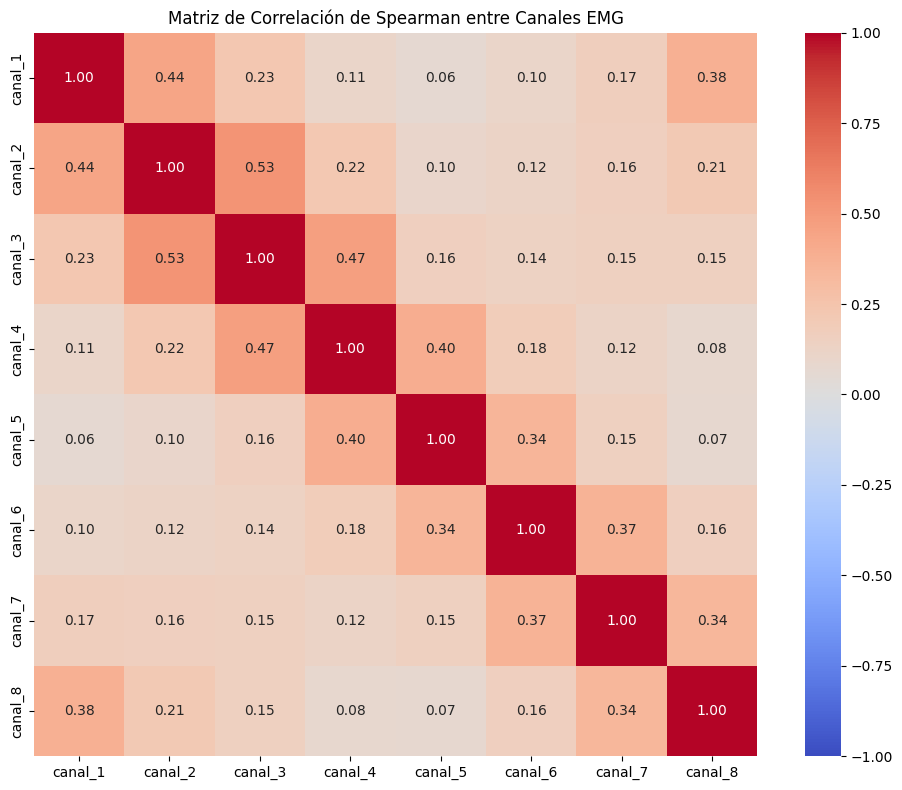

Pares de canales con alta correlación (|r| > 0.8):


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calcular la matriz de correlación entre los 8 canales EMG
canales = [f"canal_{i}" for i in range(1, 9)]
matriz_corr = datos[canales].corr(method='spearman')

# 2. Visualización mediante Mapa de Calor (Heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de Correlación de Spearman entre Canales EMG")
plt.tight_layout()
plt.show()

# 3. Comprobar pares de alta correlación (> 0.8)
print("Pares de canales con alta correlación (|r| > 0.8):")
for i in range(len(canales)):
    for j in range(i + 1, len(canales)):
        val = matriz_corr.iloc[i, j]
        if abs(val) > 0.8:
            print(f"  {canales[i]} y {canales[j]}: {val:.3f}")



#### **1. Análisis de Correlación y Relación entre Canales**
* **Comportamiento Físico de las Señales EMG:** Los 8 canales corresponden a sensores colocados de forma circular alrededor del antebrazo. Debido a la propagación del impulso bioeléctrico muscular (*crosstalk* o diafonía), los canales contiguos presentan patrones de activación similares ante un mismo movimiento.
* **Resultados de Correlación (Spearman):**
  * **Canales Adyacentes:** Muestran correlaciones moderadas (ej. `canal_1` y `canal_2` con $r \approx 0.44$; `canal_1` y `canal_8` con $r \approx 0.38$), lo que refleja la contigüidad espacial de los sensores sobre grupos musculares cercanos.
  * **Canales Opuestos:** Presentan valores de correlación cercanos a cero o muy bajos (ej. `canal_1` y `canal_5` con $r \approx 0.06$), confirmando la independencia eléctrica entre músculos antagonistas.
  * **Ausencia de Colinealidad Extrema:** No se identificaron pares de canales con correlación igual o superior a 0.80 ($\vert{}r\vert{} > 0.80$).

---

#### **2. Identificación de Redundancia y Selección de Variables**
* **Diagnóstico de Redundancia:**
  A pesar del solapamiento parcial entre canales adyacentes, **no existe redundancia estricta ni linealidad perfecta entre las variables**. Ningún canal es una réplica ni una combinación lineal directa de otro.

* **Decisión de Selección para el Modelo:**
  1. **Inclusión Total de Canales Primarios:** **Se conservan los 8 canales EMG en el dataset de entrada.** Cada canal registra la activación muscular desde una posición espacial única del antebrazo, siendo indispensable para la discriminación entre las distintas clases de gestos.
  2. **Estrategia de Transformación Espacio-Temporal:** Para aprovechar la relación entre canales y optimizar la representación del dato antes de la clasificación, el procesamiento se enfoca en:
     * **Extracción de Características por Ventana:** Transformar las señales continuas en métricas del dominio del tiempo (MAV, RMS, ZC, WL) por canal.
     * **Reducción Espacial Optativa:** En caso de requerir menor complejidad computacional en la fase de modelado, se aplica Análisis de Componentes Principales (PCA) sobre las características extraídas para conservar el 95% de la varianza explicada.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*